In [ ]:
# LOAD DATA
# EXTRACT DATA
# lookup tool 
_# DECIDE
# ACTION - EXplain



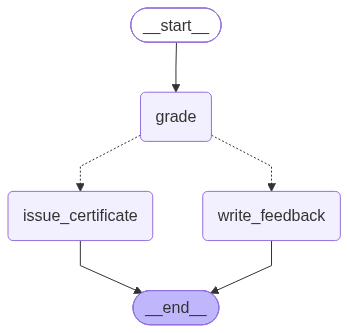

---
# Part 1 — Python building blocks

## 1.1 Plain `dict`: flexible… too flexible

A workflow passes data from step to step. The simplest container is a dict.

In [1]:
order = {"order_id": "A1", "amount": 250.0}
order["status"] = "paid"
print(order)


{'order_id': 'A1', 'amount': 250.0, 'status': 'paid'}


In [2]:
order["stauts"] = "refunded"     # typo!
print(order)

{'order_id': 'A1', 'amount': 250.0, 'status': 'paid', 'stauts': 'refunded'}


## 1.2 `TypedDict`: a dict with a declared shape

`TypedDict` describes the keys and types of a dict. Think of it as a **contract**: "this dict has these keys".

In [ ]:
from typing import TypedDict

class Student(TypedDict):
    name: str
    marks: int

s: Student = {"name": "Alice", "marks": 85}

{'name': 'Bob'}


In [ ]:
# NODES, EDGES and Shared State

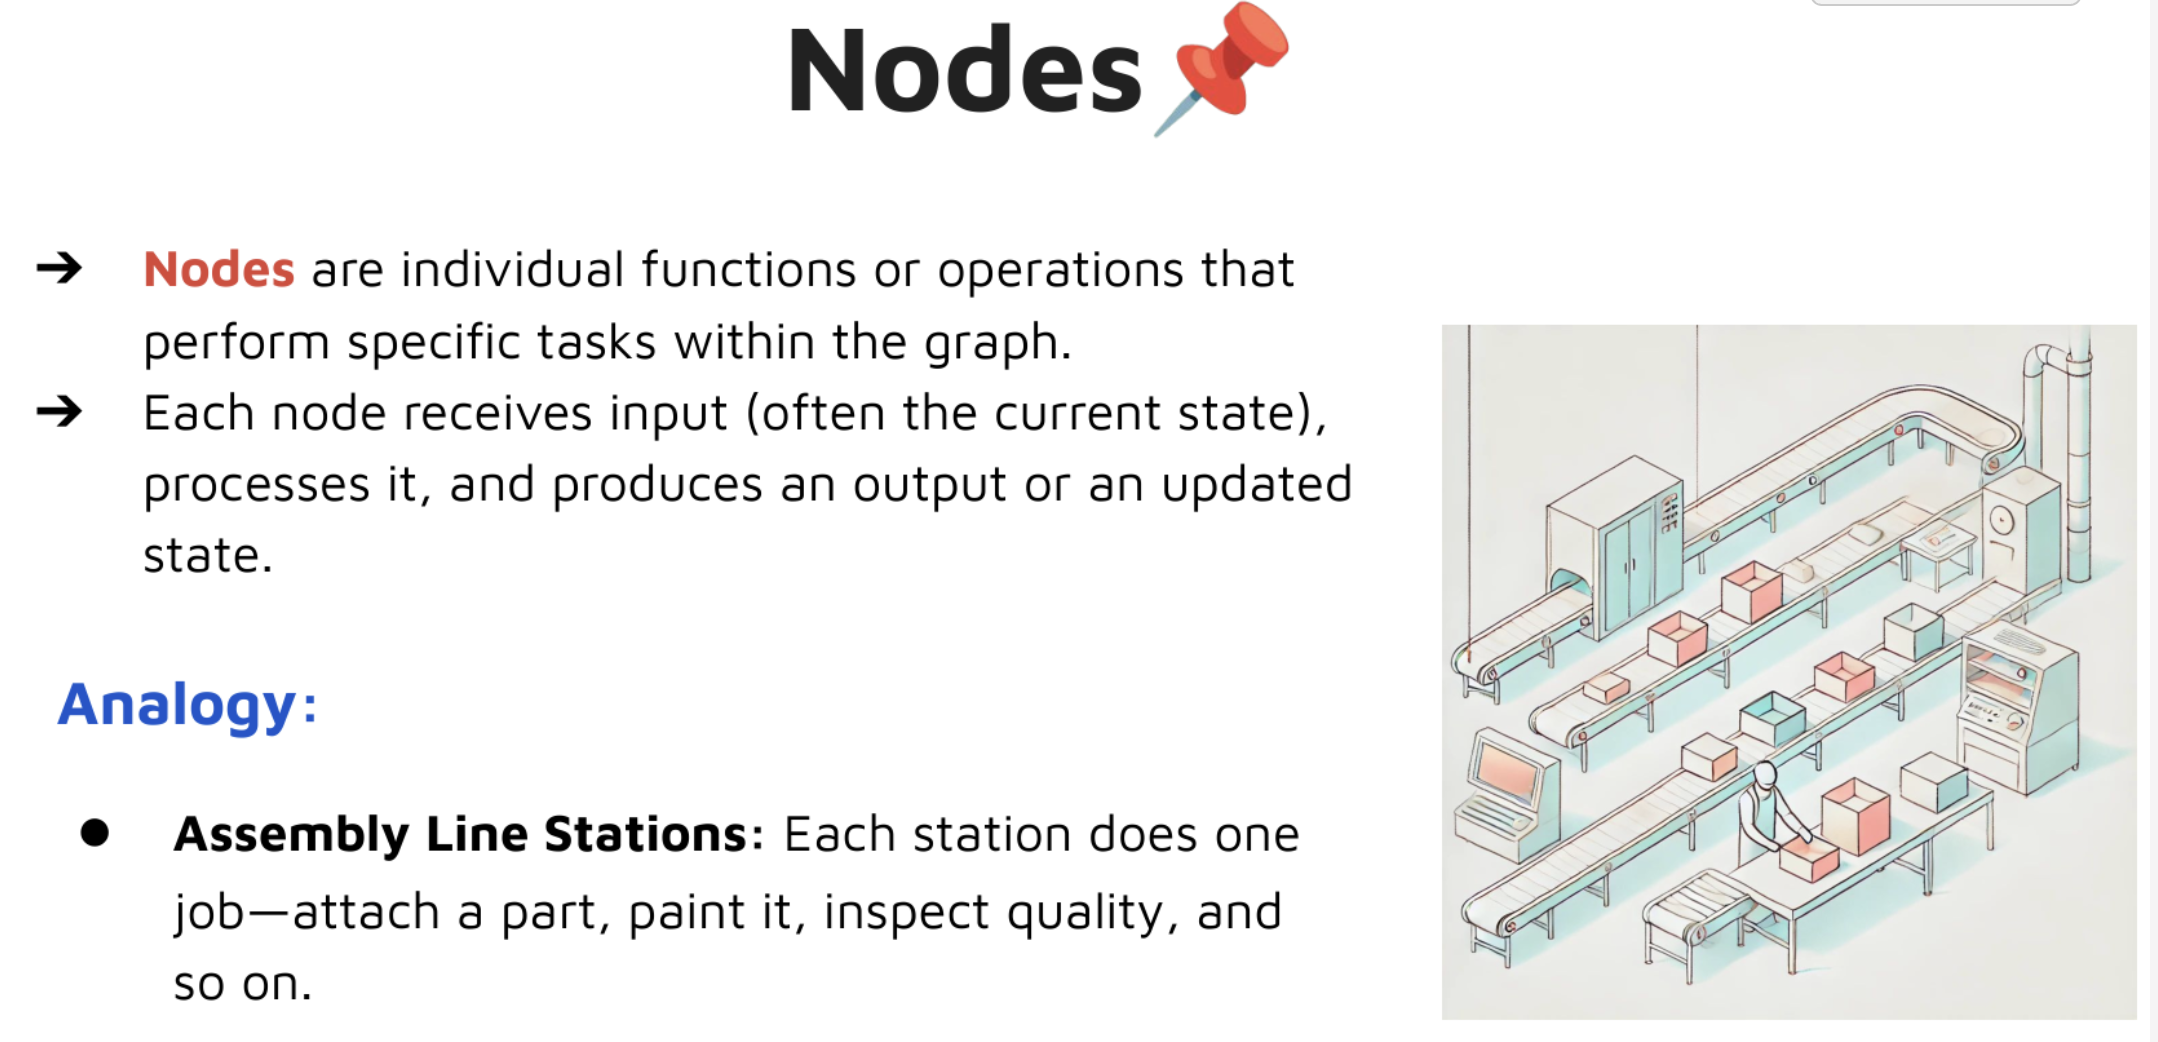

# Nodes:
    - Represent discrete steps in your workflow
    - Each node has a single responsibility (data transformation, validation, decision-making)
    - Promotes modular design that reduces complexity

    - Enables isolated testing and maintenance

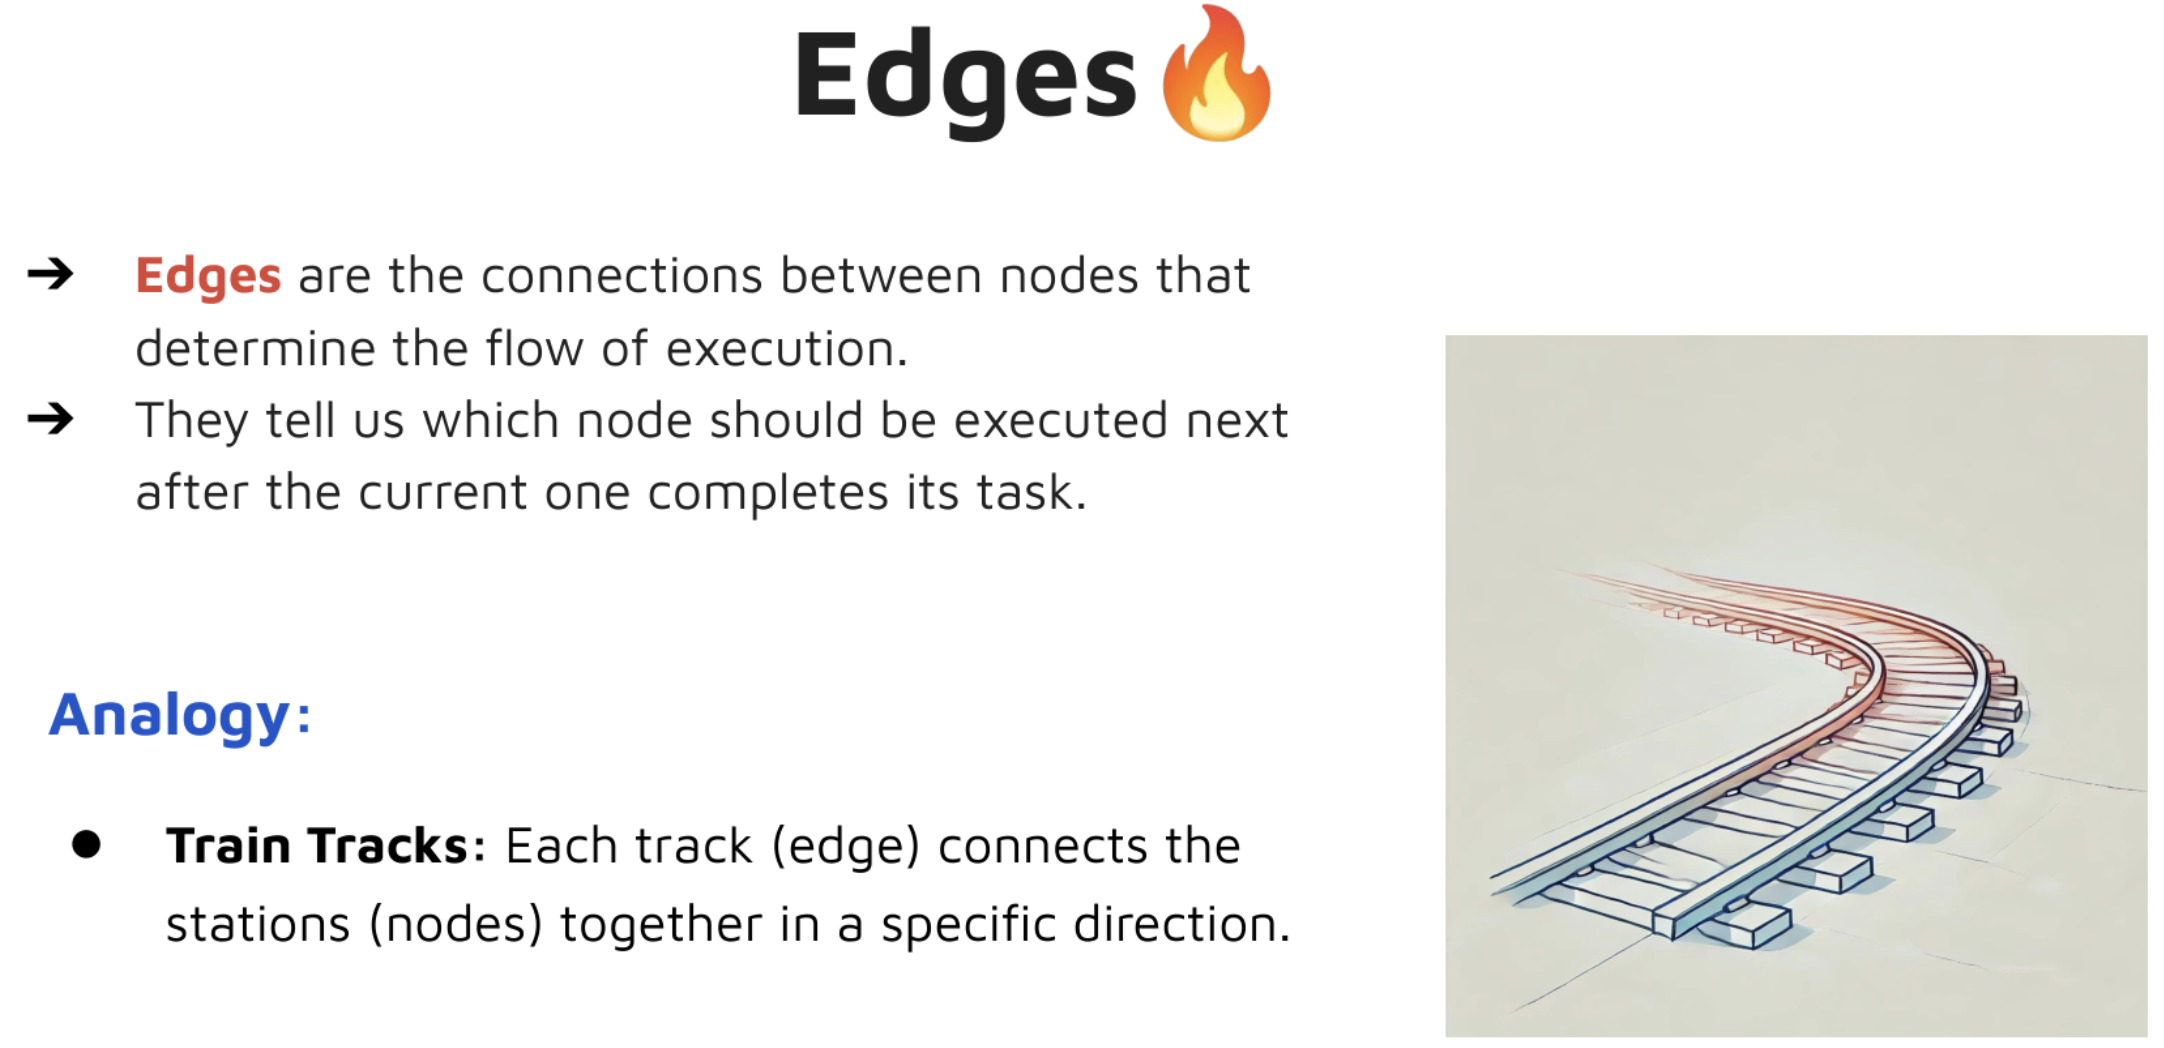

# **Edges**:
    
    - Define the order in which nodes run
    - Act as directed connections between workflow steps
    - Ensure outputs from one node become inputs to the next
    - Create explicit control over data flow

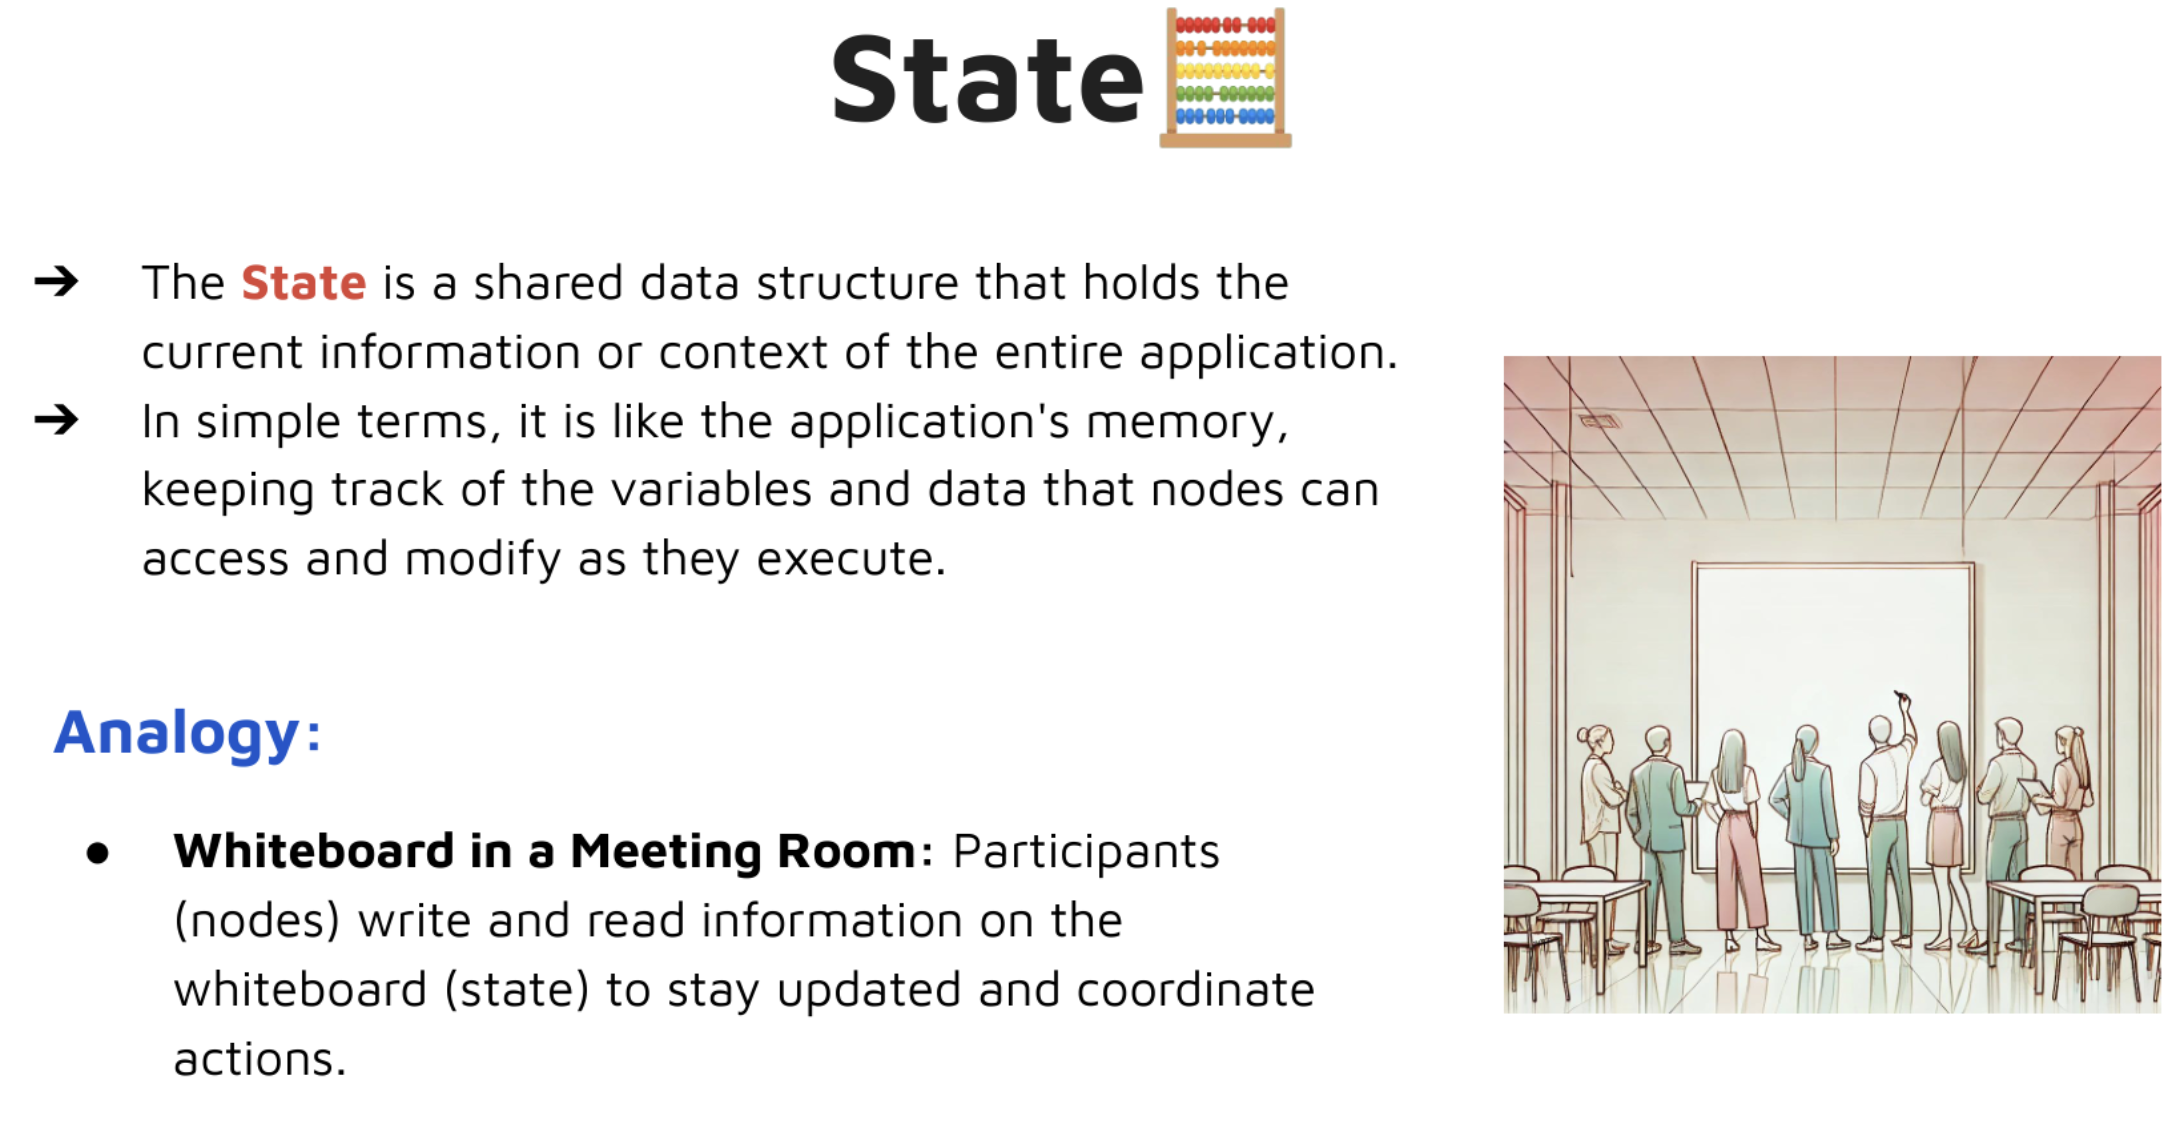

# **Shared State**:
   
	- The State is a shared data structure and represents the current snapshot of the app.
    - Carries data between nodes throughout the execution
    - Each node reads from, modifies, or augments the state according to its role
    - Avoids tight coupling seen in monolithic guard classes
    - Provides transparency about what data passes to each node

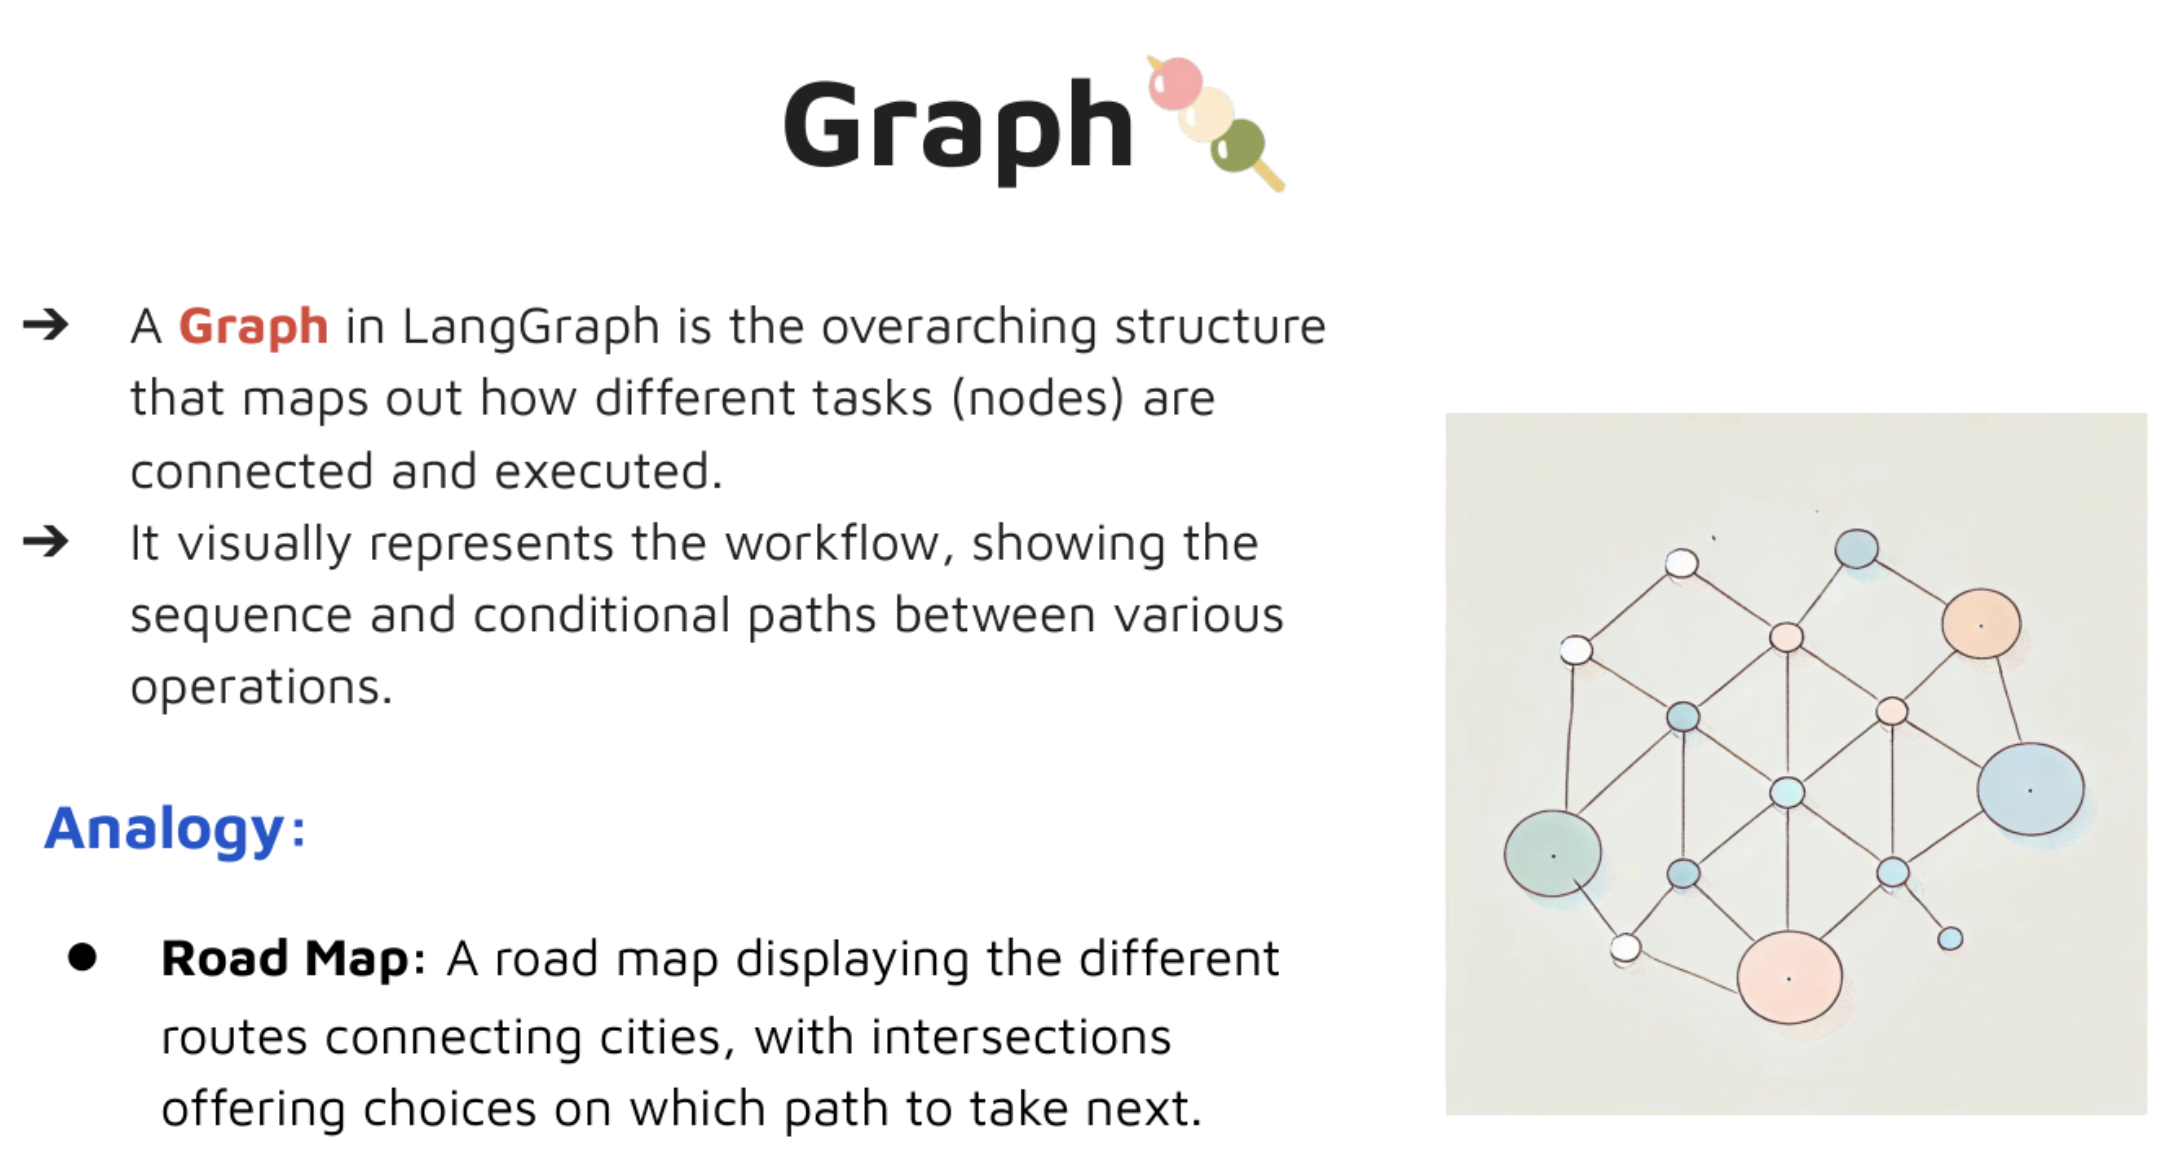

# LangGraph is created to define cyclical graphs. Graphs consist of the following elements:

- Nodes represent actual actions and can be either LLMs, agents or functions. Also, a special END node marks the end of execution.
- Edges connect nodes and determine the execution flow of your graph. There are basic edges that simply link one node to another and conditional edges that incorporate if-statements and additional logic.


### Graph (Workflow)
The overall structure that combines state, nodes, and edges into a cohesive executable process.

### State
The data structure that carries and tracks information as it moves through the workflow.

### Nodes
The individual steps in each workflow, each performing a specific task or transformation on the state.

### Edges
The connections between nodes defining the order and conditions under which transitions occur.

In [12]:
%pip install langgraph


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [15]:
from langgraph.graph import StateGraph, START, END


class InputState(TypedDict):
    string_value: str
    numeric_value: int



def modify_state(input: InputState):
    print(f"Current input: {input}")
    return input



graph = StateGraph(InputState)
graph.add_node("node_a", modify_state)
graph.add_node("node_b", modify_state)

graph.add_edge(START, "node_a")
graph.add_edge("node_a", "node_b")
graph.add_edge("node_b", END)

graph.set_entry_point("node_a")


workflow = graph.compile()






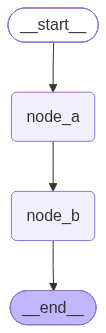

In [16]:
from IPython.display import Image

display(Image(workflow.get_graph().draw_mermaid_png()))

In [ ]:
workflow.invoke({"string_value": "a"})

Current input: {'string_value': 'a'}
Current input: {'string_value': 'a'}


{'string_value': 'a'}

In [29]:
workflow.invoke({"string_value": "a", "numeric_value": 9})

Current input: {'string_value': 'a', 'numeric_value': 9}
Current input: {'string_value': 'a', 'numeric_value': 9}


{'string_value': 'a', 'numeric_value': 9}

In [30]:
def modify_state(input: InputState):
    input['numeric_value']+=1
    input['string_value']+='a'
    return input


graph = StateGraph(InputState)

graph.add_node("node_a", modify_state)
graph.add_node("node_b", modify_state)

graph.add_edge(START, "node_a")
graph.add_edge("node_a", "node_b")

graph.add_edge("node_b", END)

runnable = graph.compile()





In [33]:
runnable.invoke({"string_value": "a", "numeric_value": 1})

{'string_value': 'aaa', 'numeric_value': 3}

In [24]:
def modify_state(input: InputState):
    input["string_value"] += "a"
    input["numeric_value"] += 1
    return input


graph = StateGraph(InputState)

graph.add_node("branch_a", modify_state)
graph.add_node("branch_b", modify_state)
graph.add_edge("branch_a", "branch_b")
graph.add_edge("branch_b", END)


graph.set_entry_point("branch_a")

runnable = graph.compile()


In [34]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [36]:
class AgentState(TypedDict):
    number1: int
    operation: str
    number2: int
    final_number:int
    

In [37]:
def adder(state: AgentState) -> AgentState:
    state["final_number"] = state["number1"] + state["number2"]
    return state

def subtractor(state: AgentState) -> AgentState:
    state["final_number"] = state["number1"] - state["number2"]
    return state



def decide_next_node(state: AgentState):
    if state["operation"] == "+":
        return "addition_operation"
    if state["operation"] == "-":
        return "subtraction_operation"

In [38]:
def passthrogh(state: AgentState):
    return state

In [ ]:
graph = StateGraph(AgentState)

graph.add_node("add_node", adder)
graph.add_node("subtract_node", subtractor)

graph.add_node("router",lambda state: state )

graph.add_edge(START, "router")

graph.add_conditional_edges("router", decide_next_node, 
                            { # EDGE: NODE
                                "addition_operation": "add_node",
                                "subtraction_operation": "subtract_node"

                            })

graph.add_edge("add_node", END)
graph.add_edge("subtract_node", END)

workflow = graph.compile()







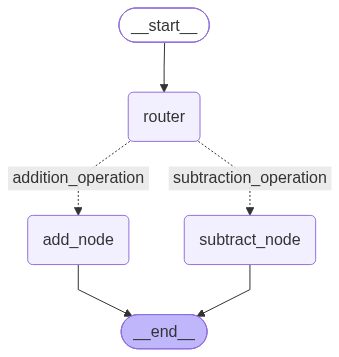

In [43]:
Image(workflow.get_graph().draw_mermaid_png())

In [44]:
state1 = AgentState(number1=10, operation="-", number2=3)

workflow.invoke(state1)

{'number1': 10, 'operation': '-', 'number2': 3, 'final_number': 7}

In [46]:
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

load_dotenv()

llm = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite",
    temperature=0,
)

In [67]:
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

load_dotenv()

llm = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite",
    temperature=0,
)


from typing import Annotated
from pydantic import BaseModel
from langgraph.graph.message import add_messages

class State(BaseModel):
    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)

def chatbot(state: State):
    print("BEFORE:", state.messages)

    response = llm.invoke(state.messages)

    update = {"messages": [response]}
    print("NODE UPDATE:", update)

    return update

graph_builder.add_node("chatbot", chatbot)

graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)


graph = graph_builder.compile()


user_input = "Answer in 20 words, Why India as better than UK?"
initial_state = State(messages=[{"role": "user", "content": user_input}])
graph.invoke(initial_state)


BEFORE: [HumanMessage(content='Answer in 20 words, Why India as better than UK?', additional_kwargs={}, response_metadata={}, id='8b4d3335-2199-42ce-b3a1-15c356932560')]
NODE UPDATE: {'messages': [AIMessage(content=[{'type': 'text', 'text': 'India offers vibrant cultural diversity, rapid economic growth, a younger demographic, and a lower cost of living than the UK.', 'extras': {'signature': 'EnMKcQFpFH0Tp2yInbBOMh92PS+jDaD5IlHKCr7Ep2zW8sIjx5yr42f+o/uVhP/Ba7hHN0JuXpDHmTH2OkzHL44IhYSXXtyWq7RCyHGKQKc3N5KyK+dqF8eAR2vx470x+S1mNsiyg4CsFVBiIerO4TaOy2tT'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1347e-21f5-7332-b280-3f4c723bafd8-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 15, 'output_tokens': 24, 'total_tokens': 39, 'input_token_details': {'cache_read': 0}})]}


{'messages': [HumanMessage(content='Answer in 20 words, Why India as better than UK?', additional_kwargs={}, response_metadata={}, id='8b4d3335-2199-42ce-b3a1-15c356932560'),
  AIMessage(content=[{'type': 'text', 'text': 'India offers vibrant cultural diversity, rapid economic growth, a younger demographic, and a lower cost of living than the UK.', 'extras': {'signature': 'EnMKcQFpFH0Tp2yInbBOMh92PS+jDaD5IlHKCr7Ep2zW8sIjx5yr42f+o/uVhP/Ba7hHN0JuXpDHmTH2OkzHL44IhYSXXtyWq7RCyHGKQKc3N5KyK+dqF8eAR2vx470x+S1mNsiyg4CsFVBiIerO4TaOy2tT'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1347e-21f5-7332-b280-3f4c723bafd8-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 15, 'output_tokens': 24, 'total_tokens': 39, 'input_token_details': {'cache_read': 0}})]}

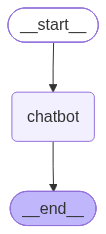

In [61]:

display(Image(graph.get_graph().draw_mermaid_png()))



In [65]:
user_input = "Answer in 20 words, Why India as better than UK?"
initial_state = State(messages=[{"role": "user", "content": user_input}])
graph.invoke(initial_state)

{'messages': [HumanMessage(content='Answer in 20 words, Why India as better than UK?', additional_kwargs={}, response_metadata={}, id='5763d623-dbd8-4369-839c-b68770c7049d'),
  AIMessage(content=[{'type': 'text', 'text': 'India offers vibrant cultural diversity, rapid economic growth, a younger demographic, and a lower cost of living than the UK.', 'extras': {'signature': 'EnMKcQFpFH0TwL/iL2rR2coOcYdJk+sAWJo5gOdjiI3ARfrGYH0oOAQgoAnlOMjbJEsXDHKJD8lpyyecdUI/WfK0Bigr1T4hjfkqNXtvM9gZ4XvHenuVksoCymC3NxVfOca1O5gKwohzyWwDFgva+NGLhEcA'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a13479-073e-7aa3-ba2a-e6742404d392-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 15, 'output_tokens': 24, 'total_tokens': 39, 'input_token_details': {'cache_read': 0}})]}

In [ ]:
class State(TypedDict):
    question: str
    answer: str

In [52]:
user_input = "Who is the PM of India?"
initial_state = State(messages=[{"role": "user", "content": user_input}])
graph.invoke(initial_state)

{'messages': [HumanMessage(content='Who is the PM of India?', additional_kwargs={}, response_metadata={}, id='9b4ee8b4-d4da-487d-aeb9-d047154cd0f0'),
  AIMessage(content=[{'type': 'text', 'text': 'The Prime Minister of India is **Narendra Modi**.', 'extras': {'signature': 'EnMKcQFpFH0TXbuOFWHl3nhY57AOjnT2ESMrTgaqeGjNy3yNsNngGJYySHYZ6OW0QrID9mkICi8M/REr6a4mMg99GIHpucgiU/9bFRiPKUX6Ou0LjJWHPBTY/AJS3CZS/PwhrnIWXBW3IjH/KASm7FVa8Aaw'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1341b-aa7c-7ee0-9b23-5221d2257765-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 11, 'total_tokens': 19, 'input_token_details': {'cache_read': 0}})]}

In [69]:

from typing import Annotated

from dotenv import load_dotenv
from pydantic import BaseModel

from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import AnyMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

load_dotenv()

llm = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite",
    temperature=0,
)


class State(BaseModel):
    messages: Annotated[list[AnyMessage], add_messages]


graph_builder = StateGraph(State)


def chatbot(state: State):
    print("\n1. STATE RECEIVED BY NODE:")
    for message in state.messages:
        print(f"{type(message).__name__}: {message.content}")

    response = llm.invoke(state.messages)

    # Return only the new AI message.
    update = {"messages": [response]}

    print("\n2. PARTIAL UPDATE RETURNED BY NODE:")
    for message in update["messages"]:
        print(f"{type(message).__name__}: {message.content}")

    return update


graph_builder.add_node("chatbot", chatbot)
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

graph = graph_builder.compile()


user_input = "Answer in 20 words: Why might someone prefer India over the UK?"

initial_state = State(
    messages=[HumanMessage(content=user_input)]
)

print("3. INITIAL STATE:")
print(initial_state)

result = graph.invoke(initial_state)

print("\n4. FINAL STATE AFTER REDUCER:")
for index, message in enumerate(result["messages"], start=1):
    print(f"{index}. {type(message).__name__}: {message.content}")

print("\nTotal messages:", len(result["messages"]))


3. INITIAL STATE:
messages=[HumanMessage(content='Answer in 20 words: Why might someone prefer India over the UK?', additional_kwargs={}, response_metadata={})]

1. STATE RECEIVED BY NODE:
HumanMessage: Answer in 20 words: Why might someone prefer India over the UK?

2. PARTIAL UPDATE RETURNED BY NODE:
AIMessage: [{'type': 'text', 'text': 'India offers a vibrant, diverse culture, warmer climate, lower cost of living, and rich historical experiences compared to the UK.', 'extras': {'signature': 'EnMKcQFpFH0T7eO0xdZbHGFOILxGz42Z/4aUC+ENURFgTPE8gWPbCQ1qaFugNe9KE6d1IxNGT+3/S4rKU2GP2BdCyK7oXAqTQj7DpcXvpfiQJwIxVijO6ZpNljgRZkXj4iqXm8sENiPrYP1nvG4rOMSfU8hH'}}]

4. FINAL STATE AFTER REDUCER:
1. HumanMessage: Answer in 20 words: Why might someone prefer India over the UK?
2. AIMessage: [{'type': 'text', 'text': 'India offers a vibrant, diverse culture, warmer climate, lower cost of living, and rich historical experiences compared to the UK.', 'extras': {'signature': 'EnMKcQFpFH0T7eO0xdZbHGFOILxG

In [54]:
%pip install gradio

  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 33.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 861.5/861.5 kB 29.0 MB/s eta 0:00:00
Using cached click-8.5.0-py3-none-any.whl (125 kB)
  Attempting uninstall: click
    Found existing installation: click 8.1.8
    Uninstalling click-8.1.8:
      Successfully uninstalled click-8.1.8
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gtts 2.5.4 requires click<8.2,>=7.1, but you have click 8.5.0 which is incompatible.

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [55]:
import gradio as gr

/Users/nickk/dev/ltm-ai-services/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
def chat(user_input: str, history):
    initial_state = State(messages=[{"role": "user", "content": user_input}])
    result = graph.invoke(initial_state)
    print(result)
    return result['messages'][-1].content


gr.ChatInterface(chat).launch()






In [ ]:
from typing import TypedDict, Annotated
from langgraph.graph import END, StateGraph
from operator import add


class InputState(TypedDict):
    no_change_value: str
    string_value: Annotated[str, add]
    numeric_value: Annotated[int, add]
    list_value: Annotated[list[str], add]

def modify_state(input: InputState):
    return input


graph = StateGraph(InputState)

graph.add_node("branch_a", modify_state)
graph.add_node("branch_b", modify_state)

graph.add_edge("branch_a", "branch_b")
graph.add_edge("branch_b", END)

graph.set_entry_point("branch_a")

runnable = graph.compile()

runnable.invoke(
    {
        "no_change_value": "a",
        "string_value": "a",
        "numeric_value": 1,
        "list_value": ["a"],
    }
)

In [72]:
runnable.invoke(
    {
        "no_change_value": "a",
        "string_value": "a",
        "numeric_value": 1,
        "list_value": ["a"],
    }
)

{'no_change_value': 'a',
 'string_value': 'aaaa',
 'numeric_value': 4,
 'list_value': ['a', 'a', 'a', 'a']}

# A reducer tells LangGraph how to combine a node's update with the existing state value.

In [73]:
# A reducer tells LangGraph how to combine a node's update with the existing state value.

In [74]:
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from operator import add


class State(TypedDict):
    score: Annotated[int, add]


def add_ten(state: State):
    return {"score": 10}


builder = StateGraph(State)

builder.add_node("add_ten", add_ten)

builder.add_edge(START, "add_ten")

builder.add_edge("add_ten", END)

graph = builder.compile()

res = graph.invoke({"score": 5})

print(res)




{'score': 15}


In [75]:
def add_ten(state: State):
    return {"score": 10}

builder = StateGraph(State)
builder.add_node("first", add_ten)
builder.add_node("second", add_ten)

builder.add_edge(START, "first")
builder.add_edge("first", "second")
builder.add_edge("second", END)

graph = builder.compile()

print(graph.invoke({"score": 5}))

{'score': 25}


In [ ]:
from typing import TypedDict, Annotated
from operator import add
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    text: Annotated[str, add]

def duplicate(state: State):
    return state

builder = StateGraph(State)
builder.add_node("first", duplicate)
builder.add_node("second", duplicate)

builder.add_edge(START, "first")
builder.add_edge("first", "second")
builder.add_edge("second", END)

graph = builder.compile()
print(graph.invoke({"text": "a"}))

{'text': 'a'}


In [78]:
class State(TypedDict):
    tasks: Annotated[list[str], add]

def task_a(state: State):
    return {"tasks": ["learn Python"]}

def task_b(state: State):
    return {"tasks": ["learn LangGraph"]}

In [79]:
builder = StateGraph(State)
builder.add_node("task_a", task_a)
builder.add_node("task_b", task_b)
builder.add_edge(START, "task_a")
builder.add_edge("task_a", "task_b")
builder.add_edge("task_b", END)

graph = builder.compile()

result = graph.invoke({"tasks": []})
print(result)

{'tasks': ['learn Python', 'learn LangGraph']}
